   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 3.1 MB/s eta 0:00:00
Downloaded 4,024 observations

Running rolling HMM...




PERFORMANCE COMPARISON
                                    Total Return    CAGR  Annual Volatility  \
Buy & Hold                                6.7095  0.1385             0.1724   
Traditional Breakout                     -0.1812 -0.0126             0.0572   
Volatility-Adjusted Breakout              0.0562  0.0035             0.0506   
HMM + Volatility-Adjusted Breakout       -0.2936 -0.0218             0.0417   

                                    Sharpe Ratio  Sortino Ratio  Max Drawdown  \
Buy & Hold                                0.8030         0.9877       -0.3372   
Traditional Breakout                     -0.2205        -0.0721       -0.3452   
Volatility-Adjusted Breakout              0.0688         0.0302       -0.1656   
HMM + Volatility-Adjusted Breakout       -0.5237        -0.2526       -0.3398   

                                    Calmar Ratio  
Buy & Hold                                0.4107  
Traditional Breakout                     -0.0365  
Volatility-Adjusted 

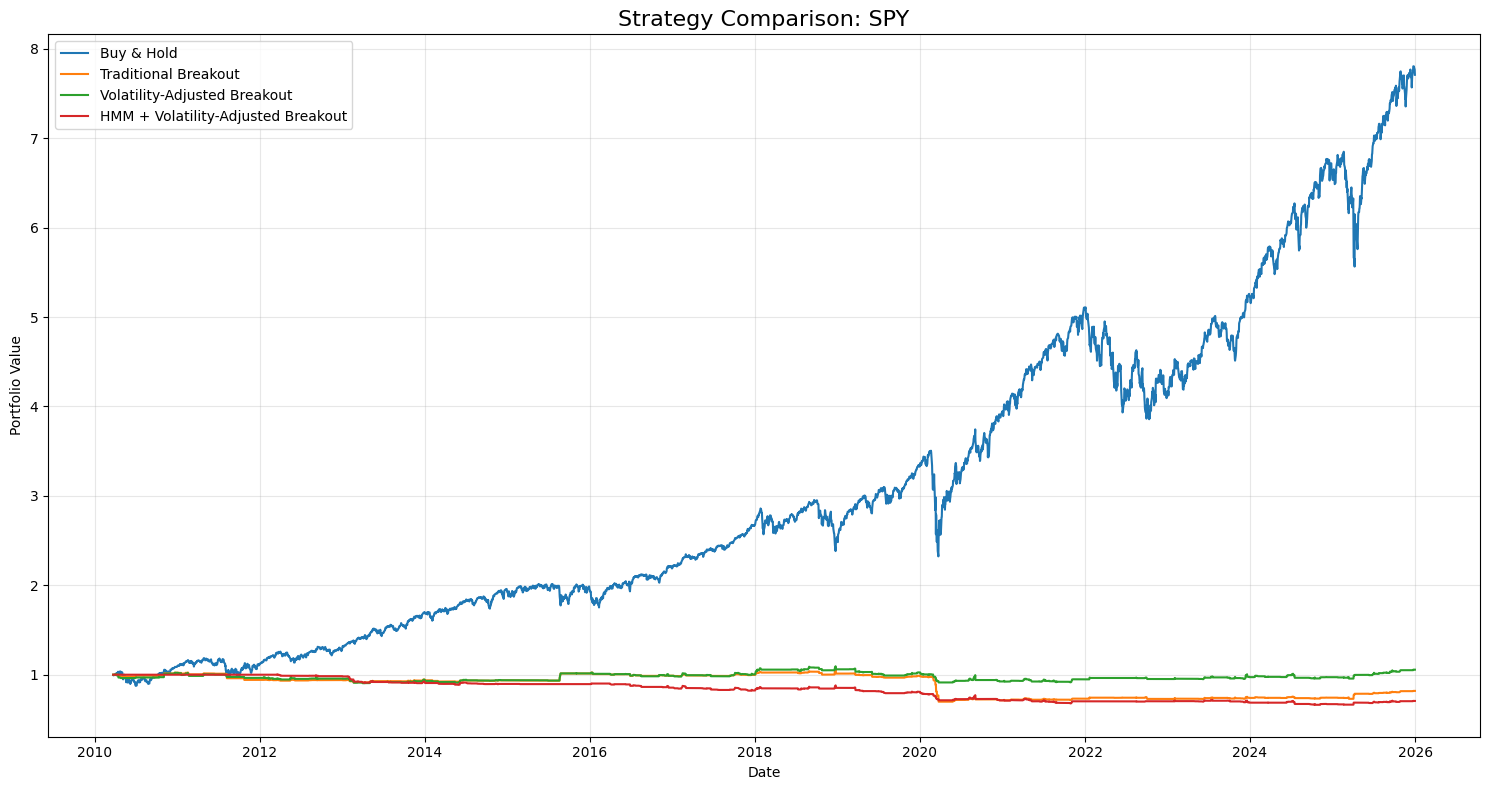



HMM REGIME DISTRIBUTION
Regime
-1    0.131267
 0    0.125976
 1    0.742756
Name: proportion, dtype: float64


PERFORMANCE BY HMM REGIME

Bearish Regime
----------------------------------------
Total Return: -9.41%
CAGR: -4.67%
Annual Volatility: 5.20%
Sharpe Ratio: -0.90
Sortino Ratio: -0.39
Max Drawdown: -13.28%
Calmar Ratio: -0.35

Neutral Regime
----------------------------------------
Total Return: 0.00%
CAGR: 0.00%
Annual Volatility: 0.00%
Sharpe Ratio: nan
Sortino Ratio: nan
Max Drawdown: 0.00%
Calmar Ratio: nan

Bullish Regime
----------------------------------------
Total Return: -22.03%
CAGR: -2.10%
Annual Volatility: 4.32%
Sharpe Ratio: -0.49
Sortino Ratio: -0.26
Max Drawdown: -26.29%
Calmar Ratio: -0.08


TRADE STATISTICS
Total signals: 379
Long signals: 358
Short signals: 21
Average volatility: 14.69%
Average position size: 0.144
Total turnover: 743.33
Total transaction costs: 0.3717


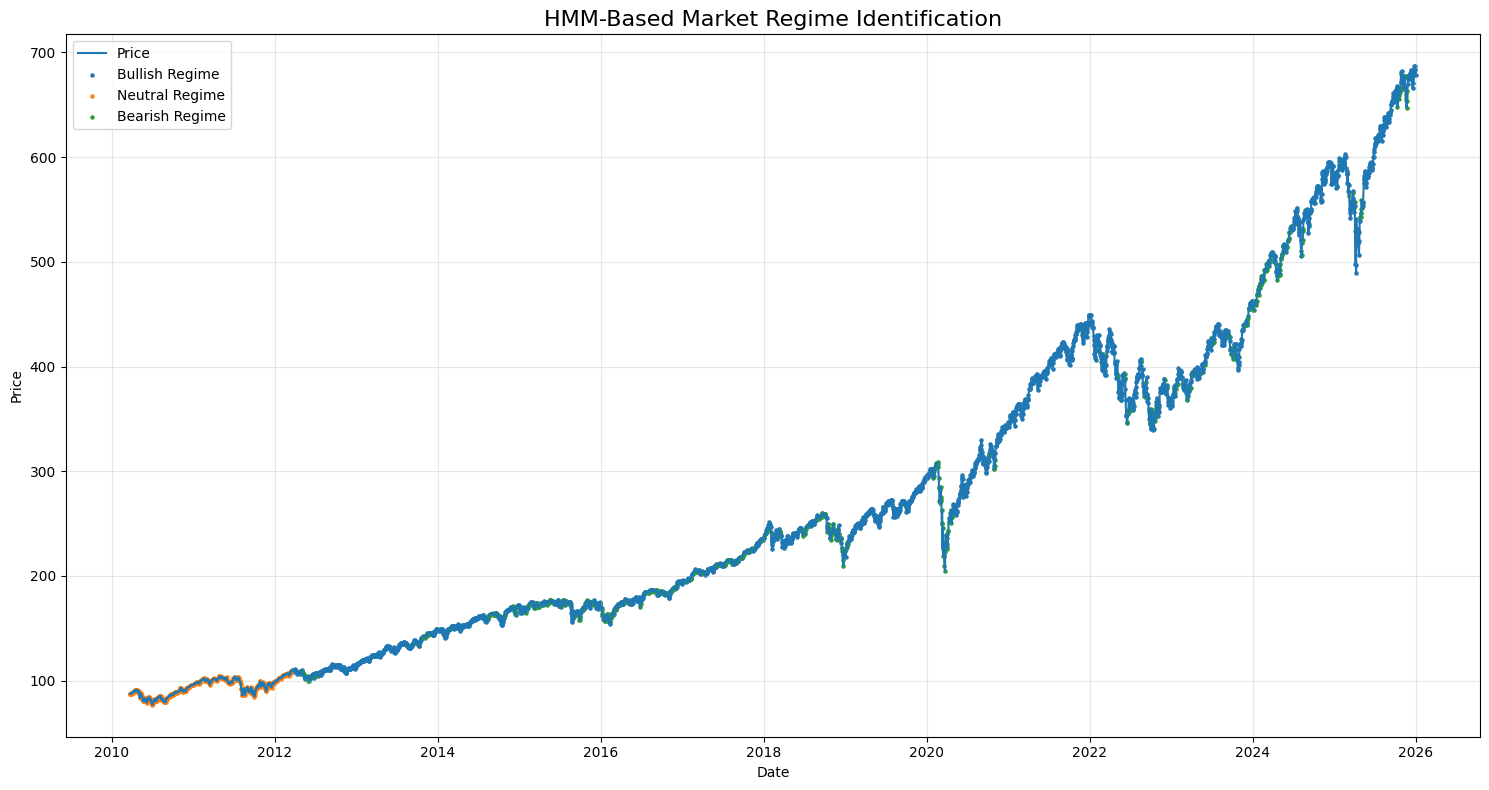

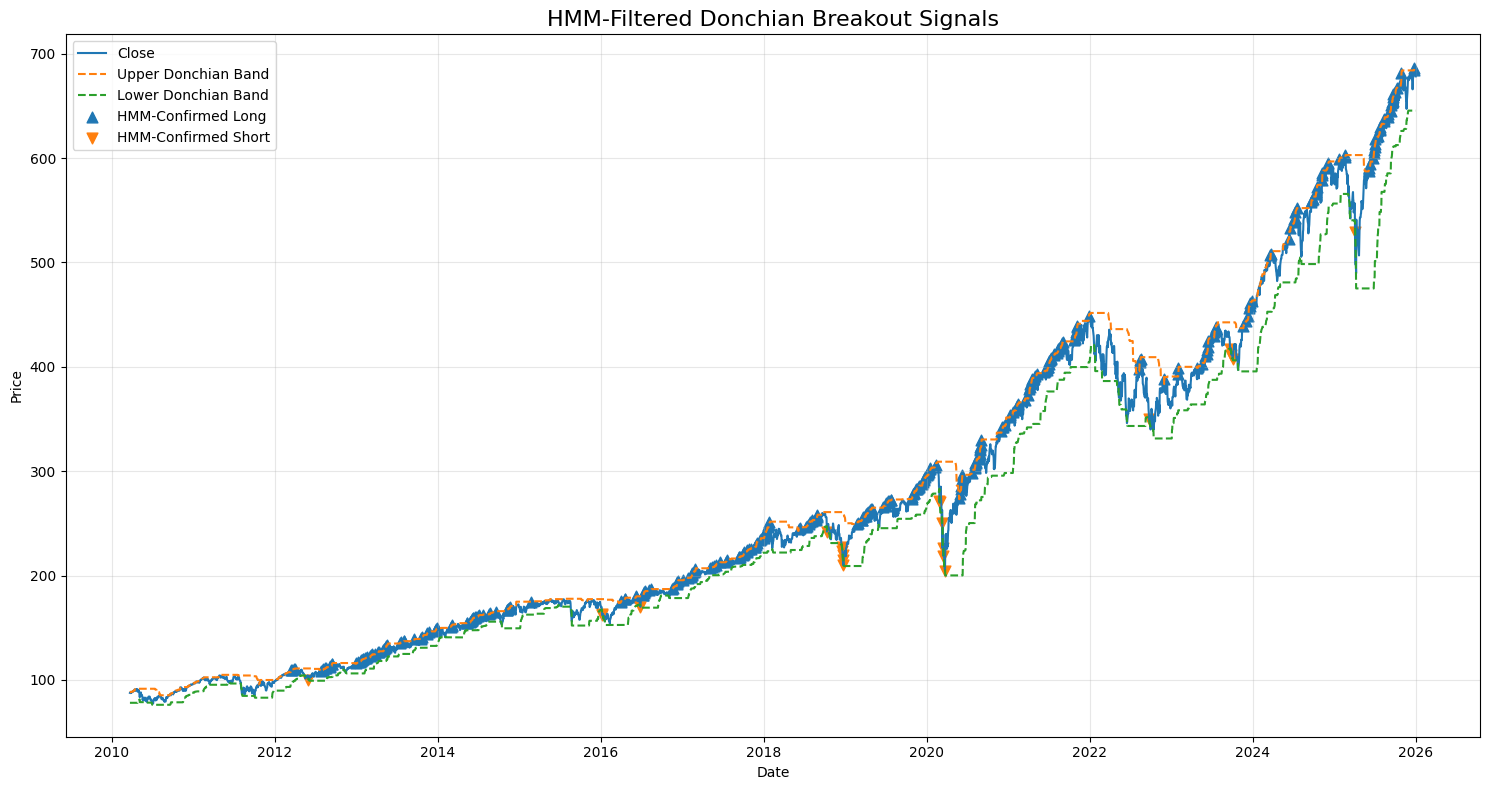



RESEARCH SUMMARY

Research Question:
Can HMM-Based Market Regime Detection Improve the Risk-Adjusted
Performance of Volatility-Adjusted Breakout Trading Strategies?

Asset:
SPY

Breakout:
55-day Donchian Breakout

HMM:
3-State Gaussian HMM

HMM Training Window:
500 observations

Volatility Target:
15%

Maximum Leverage:
2.0x

Transaction Cost:
0.05%

Core Strategy:
Breakout + HMM Regime Filter + Volatility-Based Position Sizing

BACKTEST COMPLETE


In [1]:
# ================================================================
# HMM-BASED REGIME DETECTION + VOLATILITY-ADJUSTED BREAKOUT
# ================================================================

!pip install -q yfinance hmmlearn quantstats

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from hmmlearn.hmm import GaussianHMM

# ================================================================
# 1. PARAMETERS
# ================================================================

TICKER = "SPY"

START_DATE = "2010-01-01"
END_DATE = "2026-01-01"

BREAKOUT_WINDOW = 55
ATR_WINDOW = 14
VOL_WINDOW = 20

HMM_WINDOW = 500
N_STATES = 3

TARGET_VOL = 0.15
MAX_LEVERAGE = 2.0

TRANSACTION_COST = 0.0005

# ================================================================
# 2. DOWNLOAD DATA
# ================================================================

print("Downloading market data...")

df = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[
    ["Open", "High", "Low", "Close", "Volume"]
].dropna()

print(f"Downloaded {len(df):,} observations")

# ================================================================
# 3. FEATURE ENGINEERING
# ================================================================

df["Return"] = df["Close"].pct_change()

# Realized volatility
df["Volatility"] = (
    df["Return"]
    .rolling(VOL_WINDOW)
    .std() * np.sqrt(252)
)

# Momentum
df["Momentum"] = (
    df["Close"]
    .pct_change(VOL_WINDOW)
)

# True Range
previous_close = df["Close"].shift(1)

tr1 = df["High"] - df["Low"]
tr2 = abs(df["High"] - previous_close)
tr3 = abs(df["Low"] - previous_close)

df["TR"] = pd.concat(
    [tr1, tr2, tr3],
    axis=1
).max(axis=1)

# ATR
df["ATR"] = (
    df["TR"]
    .rolling(ATR_WINDOW)
    .mean()
)

# ================================================================
# 4. DONCHIAN BREAKOUT
# ================================================================

df["Upper_Band"] = (
    df["High"]
    .rolling(BREAKOUT_WINDOW)
    .max()
    .shift(1)
)

df["Lower_Band"] = (
    df["Low"]
    .rolling(BREAKOUT_WINDOW)
    .min()
    .shift(1)
)

df["Breakout"] = 0

df.loc[
    df["Close"] > df["Upper_Band"],
    "Breakout"
] = 1

df.loc[
    df["Close"] < df["Lower_Band"],
    "Breakout"
] = -1

# ================================================================
# 5. HMM FEATURES
# ================================================================

df["HMM_Return"] = df["Return"]
df["HMM_Volatility"] = df["Volatility"]
df["HMM_Momentum"] = df["Momentum"]

df = df.dropna().copy()

feature_columns = [
    "HMM_Return",
    "HMM_Volatility",
    "HMM_Momentum"
]

# ================================================================
# 6. ROLLING HMM REGIME DETECTION
# ================================================================

print("\nRunning rolling HMM...")

df["HMM_State"] = np.nan
df["HMM_State_Return"] = np.nan

for i in range(HMM_WINDOW, len(df)):

    train_data = df.iloc[
        i-HMM_WINDOW:i
    ][feature_columns].values

    current_data = df.iloc[
        i:i+1
    ][feature_columns].values

    try:

        model = GaussianHMM(
            n_components=N_STATES,
            covariance_type="diag",
            n_iter=200,
            random_state=42
        )

        model.fit(train_data)

        # Hidden state probabilities
        state = model.predict(current_data)[0]

        df.iloc[
            i,
            df.columns.get_loc("HMM_State")
        ] = state

        # State mean return from training data
        train_states = model.predict(train_data)

        state_returns = {}

        for s in range(N_STATES):

            mask = train_states == s

            if mask.sum() > 0:
                state_returns[s] = train_data[
                    mask, 0
                ].mean()

        if state in state_returns:

            df.iloc[
                i,
                df.columns.get_loc("HMM_State_Return")
            ] = state_returns[state]

    except Exception:
        continue

df["HMM_State"] = df["HMM_State"].ffill()

df["HMM_State_Return"] = (
    df["HMM_State_Return"].ffill()
)

# ================================================================
# 7. REGIME CLASSIFICATION
# ================================================================
#
# IMPORTANT:
# State numbers themselves have no economic meaning.
# We classify the current HMM state using its expected return.
#
# Positive expected return  -> Bullish
# Negative expected return -> Bearish
# Near zero               -> Neutral
# ================================================================

df["Regime"] = 0

df.loc[
    df["HMM_State_Return"] > 0,
    "Regime"
] = 1

df.loc[
    df["HMM_State_Return"] < 0,
    "Regime"
] = -1

# ================================================================
# 8. VOLATILITY-ADJUSTED POSITION SIZING
# ================================================================

df["Vol_Adjustment"] = (
    TARGET_VOL /
    (df["Volatility"] + 1e-8)
)

df["Vol_Adjustment"] = (
    df["Vol_Adjustment"]
    .clip(
        lower=0,
        upper=MAX_LEVERAGE
    )
)

# ================================================================
# 9. HMM-FILTERED BREAKOUT SIGNAL
# ================================================================

df["Signal"] = 0

# Long:
# Breakout + bullish regime

long_condition = (
    (df["Breakout"] == 1) &
    (df["Regime"] == 1)
)

# Short:
# Breakdown + bearish regime

short_condition = (
    (df["Breakout"] == -1) &
    (df["Regime"] == -1)
)

df.loc[
    long_condition,
    "Signal"
] = 1

df.loc[
    short_condition,
    "Signal"
] = -1

# ================================================================
# 10. POSITION SIZING
# ================================================================

df["Position"] = (
    df["Signal"] *
    df["Vol_Adjustment"]
)

df["Position"] = (
    df["Position"]
    .clip(
        lower=-MAX_LEVERAGE,
        upper=MAX_LEVERAGE
    )
)

# ================================================================
# 11. SHIFT POSITION
# ================================================================
#
# Today's signal is executed using tomorrow's return.
# This prevents look-ahead bias.
# ================================================================

df["Executed_Position"] = (
    df["Position"].shift(1)
)

# ================================================================
# 12. STRATEGY RETURNS
# ================================================================

df["Gross_Strategy_Return"] = (
    df["Executed_Position"] *
    df["Return"]
)

# ================================================================
# 13. TRANSACTION COSTS
# ================================================================

df["Turnover"] = (
    df["Executed_Position"]
    .diff()
    .abs()
)

df["Transaction_Cost"] = (
    df["Turnover"] *
    TRANSACTION_COST
)

df["Net_Strategy_Return"] = (
    df["Gross_Strategy_Return"]
    - df["Transaction_Cost"]
)

# ================================================================
# 14. BUY & HOLD
# ================================================================

df["BuyHold_Return"] = df["Return"]

# ================================================================
# 15. TRADITIONAL BREAKOUT
# ================================================================

df["Traditional_Position"] = (
    df["Breakout"].shift(1)
)

df["Traditional_Breakout_Return"] = (
    df["Traditional_Position"] *
    df["Return"]
)

# ================================================================
# 16. VOLATILITY-ADJUSTED BREAKOUT
# ================================================================

df["VolAdjusted_Position"] = (
    df["Breakout"].shift(1) *
    df["Vol_Adjustment"].shift(1)
)

df["VolAdjusted_Position"] = (
    df["VolAdjusted_Position"]
    .clip(
        lower=-MAX_LEVERAGE,
        upper=MAX_LEVERAGE
    )
)

df["VolAdjusted_Breakout_Return"] = (
    df["VolAdjusted_Position"] *
    df["Return"]
)

# ================================================================
# 17. PERFORMANCE FUNCTION
# ================================================================

def performance_metrics(returns):

    returns = returns.dropna()

    if len(returns) == 0:
        return {
            "Total Return": np.nan,
            "CAGR": np.nan,
            "Annual Volatility": np.nan,
            "Sharpe Ratio": np.nan,
            "Sortino Ratio": np.nan,
            "Max Drawdown": np.nan,
            "Calmar Ratio": np.nan
        }

    equity = (
        1 + returns
    ).cumprod()

    total_return = (
        equity.iloc[-1] - 1
    )

    years = len(returns) / 252

    CAGR = (
        equity.iloc[-1] ** (1 / years) - 1
        if years > 0 else np.nan
    )

    annual_volatility = (
        returns.std() *
        np.sqrt(252)
    )

    sharpe = (
        CAGR / annual_volatility
        if annual_volatility > 0
        else np.nan
    )

    downside = returns[
        returns < 0
    ].std() * np.sqrt(252)

    sortino = (
        CAGR / downside
        if downside > 0
        else np.nan
    )

    drawdown = (
        equity /
        equity.cummax()
        - 1
    )

    max_drawdown = drawdown.min()

    calmar = (
        CAGR / abs(max_drawdown)
        if max_drawdown < 0
        else np.nan
    )

    return {
        "Total Return": total_return,
        "CAGR": CAGR,
        "Annual Volatility": annual_volatility,
        "Sharpe Ratio": sharpe,
        "Sortino Ratio": sortino,
        "Max Drawdown": max_drawdown,
        "Calmar Ratio": calmar
    }

# ================================================================
# 18. MODEL COMPARISON
# ================================================================

results = pd.DataFrame({

    "Buy & Hold":
        performance_metrics(
            df["BuyHold_Return"]
        ),

    "Traditional Breakout":
        performance_metrics(
            df["Traditional_Breakout_Return"]
        ),

    "Volatility-Adjusted Breakout":
        performance_metrics(
            df["VolAdjusted_Breakout_Return"]
        ),

    "HMM + Volatility-Adjusted Breakout":
        performance_metrics(
            df["Net_Strategy_Return"]
        )

}).T

# ================================================================
# 19. DISPLAY RESULTS
# ================================================================

print("\n")
print("=" * 100)
print("PERFORMANCE COMPARISON")
print("=" * 100)

print(
    results.round(4)
)

# ================================================================
# 20. EQUITY CURVES
# ================================================================

equity_curves = pd.DataFrame(index=df.index)

equity_curves["Buy & Hold"] = (
    1 + df["BuyHold_Return"].fillna(0)
).cumprod()

equity_curves["Traditional Breakout"] = (
    1 + df["Traditional_Breakout_Return"].fillna(0)
).cumprod()

equity_curves["Volatility-Adjusted Breakout"] = (
    1 + df["VolAdjusted_Breakout_Return"].fillna(0)
).cumprod()

equity_curves["HMM + Volatility-Adjusted Breakout"] = (
    1 + df["Net_Strategy_Return"].fillna(0)
).cumprod()

plt.figure(figsize=(15, 8))

for column in equity_curves.columns:

    plt.plot(
        equity_curves.index,
        equity_curves[column],
        label=column
    )

plt.title(
    f"Strategy Comparison: {TICKER}",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Portfolio Value")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 21. HMM REGIME DISTRIBUTION
# ================================================================

print("\n")
print("=" * 70)
print("HMM REGIME DISTRIBUTION")
print("=" * 70)

regime_distribution = (
    df["Regime"]
    .value_counts(normalize=True)
    .sort_index()
)

print(
    regime_distribution
)

# ================================================================
# 22. REGIME PERFORMANCE
# ================================================================

print("\n")
print("=" * 70)
print("PERFORMANCE BY HMM REGIME")
print("=" * 70)

for regime, name in [
    (-1, "Bearish"),
    (0, "Neutral"),
    (1, "Bullish")
]:

    regime_returns = df.loc[
        df["Regime"] == regime,
        "Net_Strategy_Return"
    ]

    if len(regime_returns) > 0:

        metrics = performance_metrics(
            regime_returns
        )

        print(f"\n{name} Regime")
        print("-" * 40)

        for key, value in metrics.items():

            if isinstance(value, (float, np.floating)):

                if "Ratio" in key:
                    print(
                        f"{key}: {value:.2f}"
                    )

                else:
                    print(
                        f"{key}: {value:.2%}"
                    )

# ================================================================
# 23. TRADE STATISTICS
# ================================================================

signals = df[
    df["Signal"] != 0
].copy()

print("\n")
print("=" * 70)
print("TRADE STATISTICS")
print("=" * 70)

print(
    f"Total signals: {len(signals):,}"
)

print(
    f"Long signals: "
    f"{(signals['Signal'] == 1).sum():,}"
)

print(
    f"Short signals: "
    f"{(signals['Signal'] == -1).sum():,}"
)

print(
    f"Average volatility: "
    f"{df['Volatility'].mean():.2%}"
)

print(
    f"Average position size: "
    f"{df['Position'].abs().mean():.3f}"
)

print(
    f"Total turnover: "
    f"{df['Turnover'].sum():.2f}"
)

print(
    f"Total transaction costs: "
    f"{df['Transaction_Cost'].sum():.4f}"
)

# ================================================================
# 24. HMM STATE VISUALIZATION
# ================================================================

plt.figure(figsize=(15, 8))

plt.plot(
    df.index,
    df["Close"],
    label="Price"
)

bullish = df["Regime"] == 1
neutral = df["Regime"] == 0
bearish = df["Regime"] == -1

plt.scatter(
    df.index[bullish],
    df.loc[bullish, "Close"],
    s=5,
    label="Bullish Regime"
)

plt.scatter(
    df.index[neutral],
    df.loc[neutral, "Close"],
    s=5,
    label="Neutral Regime"
)

plt.scatter(
    df.index[bearish],
    df.loc[bearish, "Close"],
    s=5,
    label="Bearish Regime"
)

plt.title(
    "HMM-Based Market Regime Identification",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 25. BREAKOUT SIGNAL VISUALIZATION
# ================================================================

plt.figure(figsize=(15, 8))

plt.plot(
    df.index,
    df["Close"],
    label="Close"
)

plt.plot(
    df.index,
    df["Upper_Band"],
    linestyle="--",
    label="Upper Donchian Band"
)

plt.plot(
    df.index,
    df["Lower_Band"],
    linestyle="--",
    label="Lower Donchian Band"
)

long_entries = (
    df["Signal"] == 1
)

short_entries = (
    df["Signal"] == -1
)

plt.scatter(
    df.index[long_entries],
    df.loc[long_entries, "Close"],
    marker="^",
    s=60,
    label="HMM-Confirmed Long"
)

plt.scatter(
    df.index[short_entries],
    df.loc[short_entries, "Close"],
    marker="v",
    s=60,
    label="HMM-Confirmed Short"
)

plt.title(
    "HMM-Filtered Donchian Breakout Signals",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 26. FINAL RESEARCH SUMMARY
# ================================================================

print("\n")
print("=" * 100)
print("RESEARCH SUMMARY")
print("=" * 100)

print(f"""
Research Question:
Can HMM-Based Market Regime Detection Improve the Risk-Adjusted
Performance of Volatility-Adjusted Breakout Trading Strategies?

Asset:
{TICKER}

Breakout:
{BREAKOUT_WINDOW}-day Donchian Breakout

HMM:
{N_STATES}-State Gaussian HMM

HMM Training Window:
{HMM_WINDOW} observations

Volatility Target:
{TARGET_VOL:.0%}

Maximum Leverage:
{MAX_LEVERAGE:.1f}x

Transaction Cost:
{TRANSACTION_COST:.2%}

Core Strategy:
Breakout + HMM Regime Filter + Volatility-Based Position Sizing
""")

print("=" * 100)
print("BACKTEST COMPLETE")
print("=" * 100)